# Next week's move in CL2 âˆ’ CL1

This notebook is the coursework estimation. **Every series is read from `data/raw/Oil Data.xlsx`.** Nothing else is used as data.

| What | Sheet in Oil Data.xlsx | How it enters |
| --- | --- | --- |
| CL1 and CL2, hence the spread | `Industry_D` | Last daily session on or before each Friday |
| Crude-stock change, rig count, production, commercial positions | `Industry_W` | The Friday row. Stock change, rig change, production change and the position change are lagged one week |
| 3-month yield, 10-year yield, VIX, dollar | `Macro_M` | Comparisons only. Latest month-end on or before that Friday |
| Industrial production | `Macro_M` | Comparisons only. Previous month's change |
| Gasoline | `StockPrices_M` | Comparisons only. Previous month's change |

The definitions sheet names the window December 1994 to June 2024. The panel is every Friday from 30 December 1994 through 28 June 2024.

## The model we report

$$
\Delta S_{t+1} = a + b\, S_t + c\, \Delta \text{Stocks}_{t-1} + d\, \Delta \text{Rigs}_{t-1} + e_{t+1}
$$

$S_t = \text{CL2}_t - \text{CL1}_t$ on that Friday, in dollars per barrel. Positive means contango. $\Delta S_{t+1}$ is the change to the next Friday.

Fitted on target weeks through 28 December 2018, Neweyâ€“West standard errors, seven lags:

- $b = -0.133$ on today's spread (p < 0.001). Each extra dollar of contango is associated with about 13 cents of pullback next week. With stocks and rigs at zero, the fitted change from a $1 spread is about 11 cents. The equation settles near 20 cents of contango.
- $c > 0$ on last week's stock change (p = 0.013). A build lines up with a slightly wider contango, about 3.1 cents for a one-standard-deviation move on the estimation sample, about 4,030.
- $d$ on the rig count is not distinguishable from zero (p = 0.38).

On the 287 holdout weeks, 4 January 2019 through 28 June 2024, this regression has a root-mean-square error of $0.48, against $0.49 for predicting no change. The spread on its own is a fraction of a cent better. ARIMA, ARIMAX and ridge are worse than no change. LASSO, which is offered the monthly yield curve, does not beat the short regression.

The cells below rebuild the Friday panel from the workbook, refit the reported regression, and read the holdout forecasts written by `coursework/analysis.py`. Running that program is what re-estimates every comparison week by week.


## 1. Open the workbook

The path is resolved by looking for `data/raw/Oil Data.xlsx`. The loader refuses any other file.


In [1]:
import importlib.util
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / "Oil Data.xlsx").exists())
spec = importlib.util.spec_from_file_location("spread_analysis", REPO / "coursework" / "analysis.py")
analysis = importlib.util.module_from_spec(spec)
spec.loader.exec_module(analysis)

print(analysis.RAW.resolve())
print("sheets used: Industry_D, Industry_W, Macro_M, StockPrices_M")
print("reported regressors:", analysis.OLS_COLS)
print("holdout starts with target Friday", analysis.HOLDOUT_START.date())


C:\Users\zhizh\Desktop\oil forecasting CW\data\raw\Oil Data.xlsx
sheets used: Industry_D, Industry_W, Macro_M, StockPrices_M
reported regressors: ['spread', 'stock_change', 'rig_change']
holdout starts with target Friday 2019-01-04


## 2. Build the Friday panel

`Industry_W` is a continuous set of Fridays and has no CL1 or CL2. `build` takes CL1, CL2 and the crack from `Industry_D` with a backward match, so a Friday never receives a later session. `price_lag_days` is zero when Friday itself traded, and one or two when the previous session is used. The stock, rig, production and position changes on a row are last week's, so they are known at this Friday's close. Yields, VIX and the dollar are attached from a month-end on or before that Friday. Industrial production and gasoline enter as the previous month's change.


In [2]:
data, provenance = analysis.build()
pd.Series(provenance)


file                                                           data/raw/Oil Data.xlsx
resolved_path                       C:\Users\zhizh\Desktop\oil forecasting CW\data...
spread_from                                            Industry_D columns CL1 and CL2
industry_from                                                              Industry_W
macro_from                            Macro_M, last month-end on or before the Friday
gasoline_from                                  StockPrices_M, previous month's change
window                                                       [1994-12-30, 2024-06-28]
fridays                                                                          1540
fridays_using_an_earlier_session                                                   66
max_price_lag_days                                                                  2
daily_rows_without_a_date                                                         534
dtype: object

In [3]:
cols = ["Date", "price_date", "price_lag_days", "CL1", "CL2", "spread", "target_date", "stock_change", "rig_change"]
data[cols].head(8)


,Date,price_date,price_lag_days,CL1,CL2,spread,target_date,stock_change,rig_change
0,1994-12-30,1994-12-30,0,17.76,17.71,-0.05,1995-01-06,NaN,NaN
1,1995-01-06,1995-01-06,0,17.67,17.62,-0.05,1995-01-13,-7390.0,NaN
2,1995-01-13,1995-01-13,0,17.52,17.46,-0.06,1995-01-20,1934.0,-20.0
3,1995-01-20,1995-01-20,0,18.65,18.42,-0.23,1995-01-27,-1282.0,11.0
4,1995-01-27,1995-01-27,0,17.95,17.86,-0.09,1995-02-03,-6414.0,-20.0
5,1995-02-03,1995-02-03,0,18.78,18.47,-0.31,1995-02-10,-281.0,-4.0
6,1995-02-10,1995-02-10,0,18.46,18.30,-0.16,1995-02-17,3153.0,4.0
7,1995-02-17,1995-02-17,0,18.91,18.73,-0.18,1995-02-24,-6334.0,2.0


The first rows show the join. `Date` is the Friday from `Industry_W`. `price_date` is the session from `Industry_D` whose CL1 and CL2 were used. Where they differ, the price is earlier than the Friday, never later.


## 3. Stationarity, through 2018 only

Tests use weeks whose target Friday is before 4 January 2019. CL1 and CL2 are tested with a trend. If those levels are unit roots, the dependent variable has to be the change in the spread rather than the flat price.


In [4]:
stationarity = analysis.stationarity(data)
stationarity


,n,adf_stat,adf_p,adf_lags,adf_5pct,kpss_stat,kpss_p,kpss_5pct,series
0,1243,-2.645184,2.595391e-01,8,-3.414028,0.730577,0.01,0.146,CL1
1,1241,-2.488451,3.337601e-01,10,-3.414034,0.754909,0.01,0.146,CL2
2,1245,-5.384248,3.655029e-06,6,-2.863864,1.040282,0.01,0.463,spread CL2-CL1
3,1239,-13.028141,2.375768e-24,12,-2.863876,0.008704,0.10,0.463,change in the spread
4,1241,-10.888703,1.240898e-19,9,-2.863872,0.111424,0.10,0.463,"stock change, lagged"
5,1243,-6.875311,1.479771e-09,6,-2.863868,0.125884,0.10,0.463,"rig change, lagged"
6,1237,-8.663149,4.762195e-14,9,-2.863879,0.098061,0.10,0.463,"yield-curve change, carried month"


## 4. The reported regression

One fit, on target weeks through 28 December 2018. The standard errors are Neweyâ€“West because the residuals are heteroskedastic and, at a weekly frequency, serially correlated. The Chow split is the middle of this sample. The recursive plot stops in 2018.


In [5]:
diag = analysis.diagnostics(data)
coefficients = pd.read_csv(analysis.OUT / "coefficients.csv")
tests = pd.read_csv(analysis.OUT / "diagnostics.csv")
print(
    f"n = {diag['n']}, {diag['from']} to {diag['to']}, "
    f"RÂ² = {diag['r_squared']:.3f}, Neweyâ€“West lags = {diag['nw_lags']}"
)
display(coefficients)
tests


n = 1250, 1995-01-20 to 2018-12-28, RÂ² = 0.069, Neweyâ€“West lags = 7


,term,estimate,hac_se,hac_t,hac_p
0,intercept,0.026926,0.012391,2.172916,2.978665e-02
1,spread,-0.133145,0.023998,-5.548136,2.887310e-08
2,stock_change,0.000008,0.000003,2.493094,1.266352e-02
3,rig_change,-0.000799,0.000904,-0.883398,3.770215e-01


,test,stat,p_value
0,Durbin-Watson,2.410436,NaN
1,"Breusch-Godfrey, 4 lags",147.516797,6.930978e-31
2,Ljung-Box lag 1,52.830777,3.635596e-13
3,Ljung-Box lag 4,122.843302,1.319019e-25
4,Ljung-Box lag 12,177.998609,1.098135e-31
5,Breusch-Pagan,116.730788,3.903354e-25
6,Chow break at target week 2007-01-12,4.170056,2.329293e-03
7,CUSUM,2.132504,2.244176e-04


The slope on the spread is the dominant term, and it is negative. The stock change is positive and detectable: a build lines up with more contango next week. The rig count is not. Durbinâ€“Watson is 2.41. Ljungâ€“Box rejects at one, four and twelve weeks, and Breuschâ€“Godfrey rejects at four weeks, which is why the standard errors are Neweyâ€“West. The ARIMA comparison is a model of the spread, not of these residuals. Breuschâ€“Pagan rejects constant variance. Chow and CUSUM reject a constant regression. The chart underneath shows what that means for the slope: the sign stays negative, and the size moves.


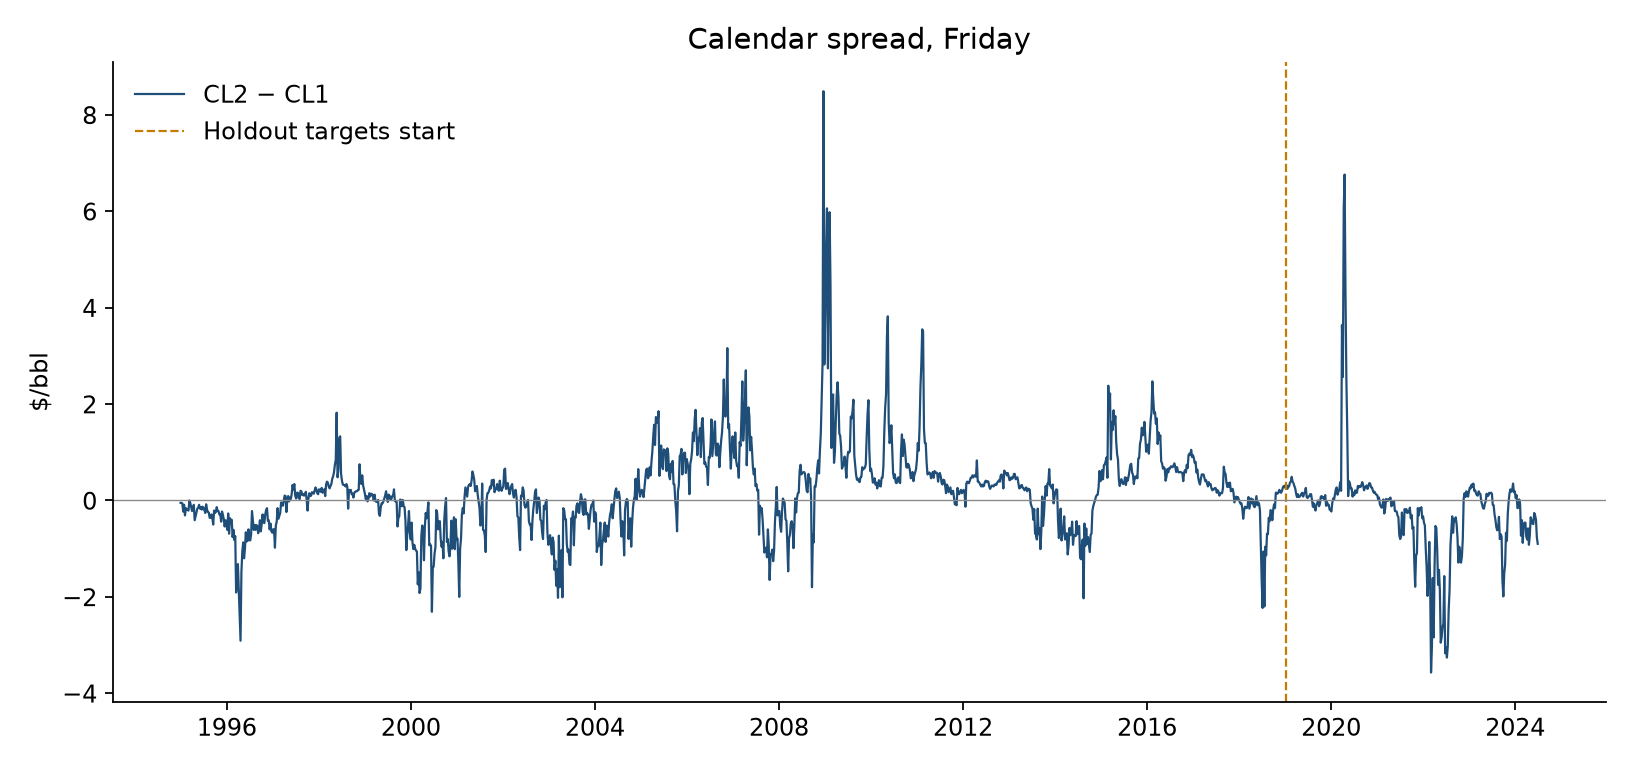

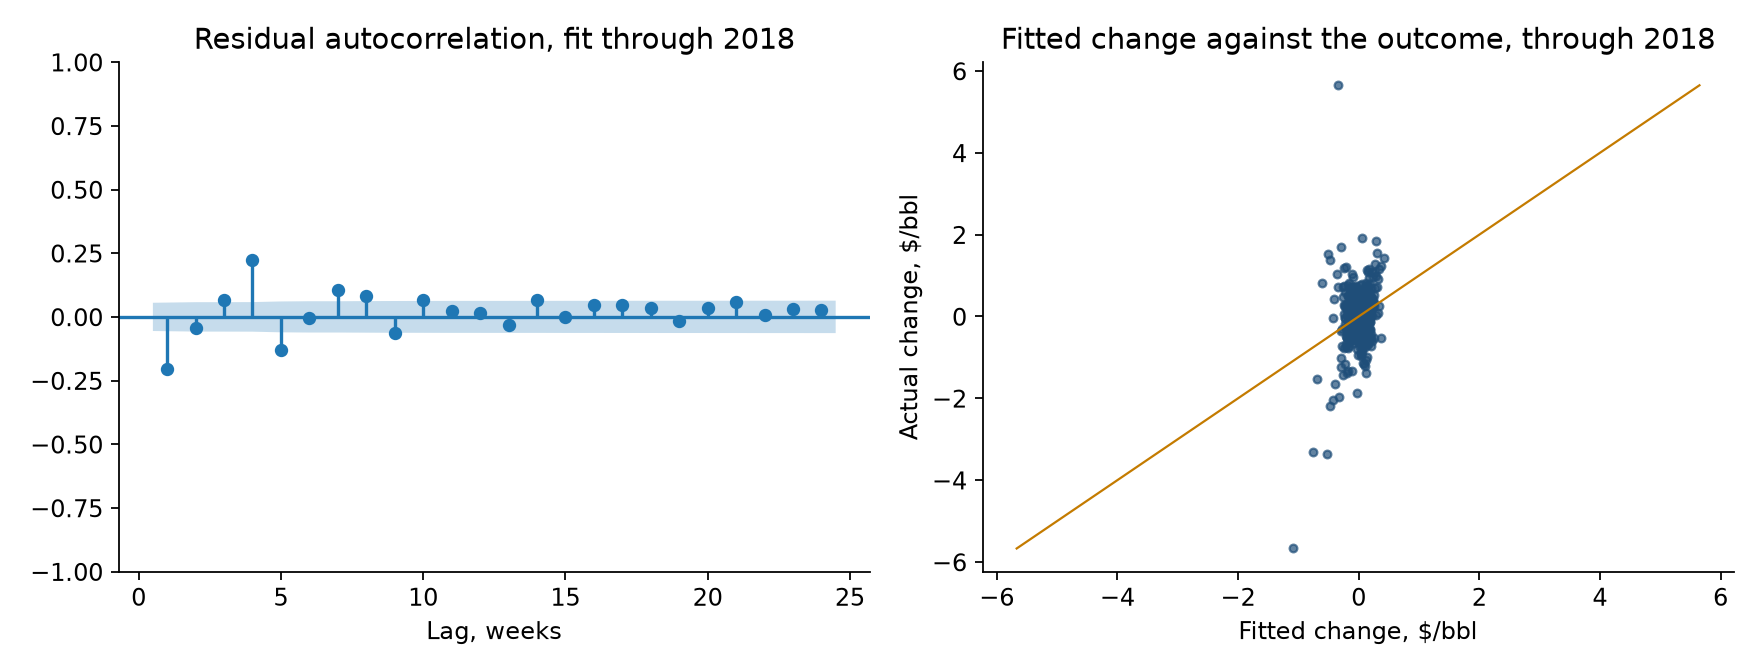

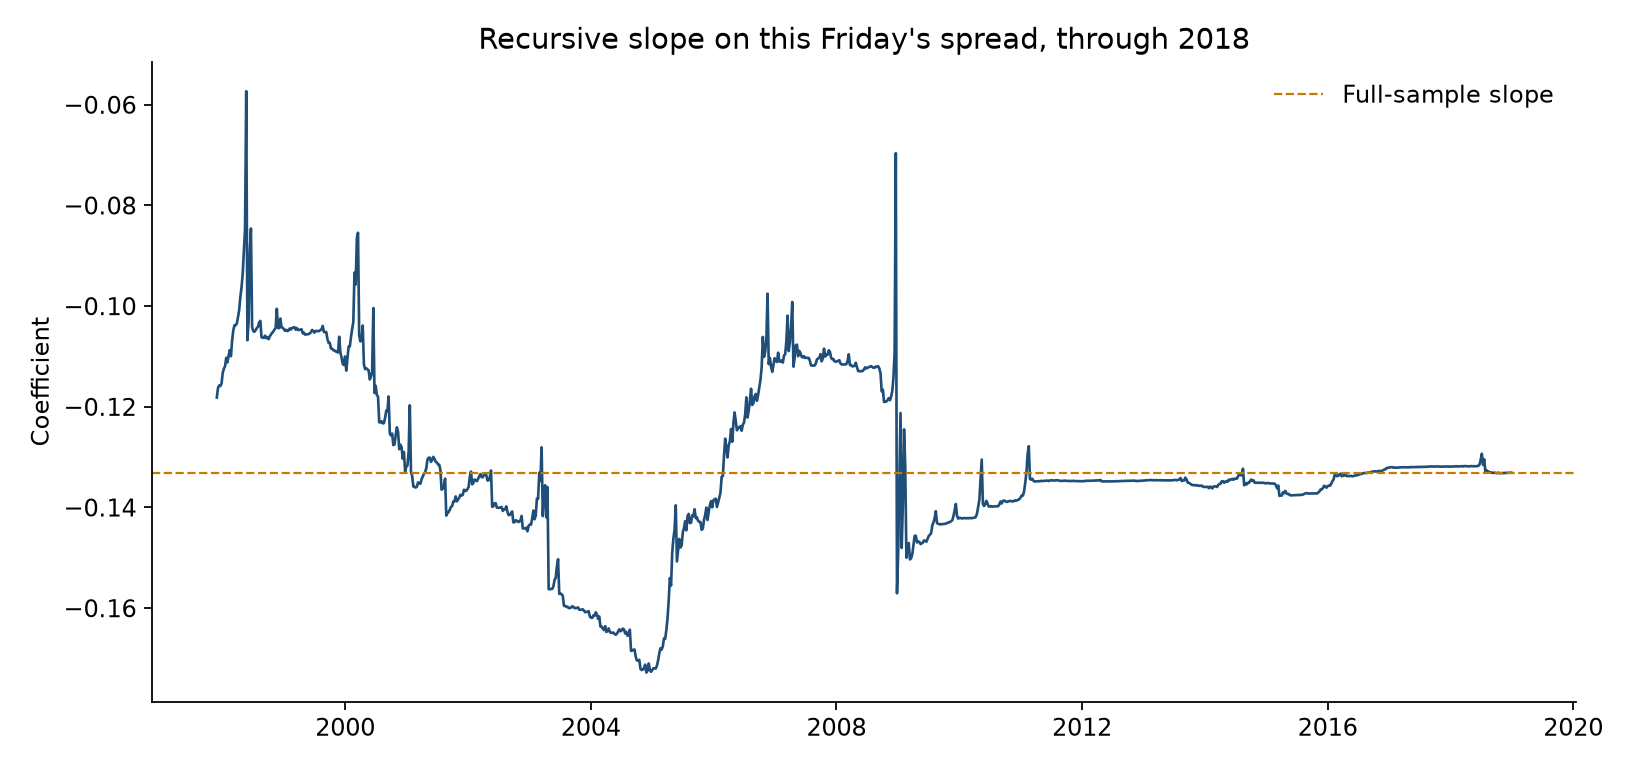

In [6]:
from IPython.display import Image, display as show

show(Image(analysis.OUT / "spread.png"))
show(Image(analysis.OUT / "fit.png"))
show(Image(analysis.OUT / "stability.png"))


## 5. Holdout comparisons

These forecasts were produced by `forecast` in `analysis.py`. For each target Friday from 4 January 2019 through 28 June 2024 the fit uses only earlier Fridays. The reported regression keeps every earlier Friday that has the spread, the stock change and the rig change. Ridge and LASSO omit seven Fridays in January and February 1995 that do not yet have the monthly series. The order of the ARIMA and the ARIMAX was chosen on the pre-2019 spread. Ridge's penalty is fixed at 10. LASSO chooses its penalty inside the training window. The monthly yield curve is in that wider set and is not in the reported regression.

Re-running the week-by-week loop takes a few minutes. It is the block at the bottom of `analysis.py`. The table here is the loop's saved output.


In [7]:
metrics = pd.read_csv(analysis.OUT / "metrics.csv")
forecasts = pd.read_csv(analysis.OUT / "forecasts.csv")
print(forecasts["target_date"].iloc[0], "to", forecasts["target_date"].iloc[-1], "n =", len(forecasts))
print("largest move")
display(forecasts.loc[forecasts["actual_change"].abs().idxmax(), ["target_date", "spread", "ols", "actual_change"]])
metrics


2019-01-04 to 2024-06-28 n = 287
largest move


target_date      2020-04-10
spread                 2.56
ols               -0.151917
actual_change           3.5
Name: 66, dtype: object

,model,n,rmse,mae,oos_r2_vs_no_change,direction_hit_rate
0,No change,287,0.487966,0.233833,NaN,NaN
1,"OLS: spread, stocks, rigs",287,0.482010,0.232193,0.024262,0.494774
2,OLS: spread only,287,0.478532,0.228093,0.038295,0.540070
3,ARIMA,287,0.505224,0.238303,-0.071983,0.540070
4,ARIMAX: stocks and rigs,287,0.511781,0.260688,-0.099991,0.529617
5,"Ridge, wider set",287,0.495522,0.254301,-0.031209,0.484321
6,"LASSO, wider set",287,0.485157,0.238146,0.011483,0.480836


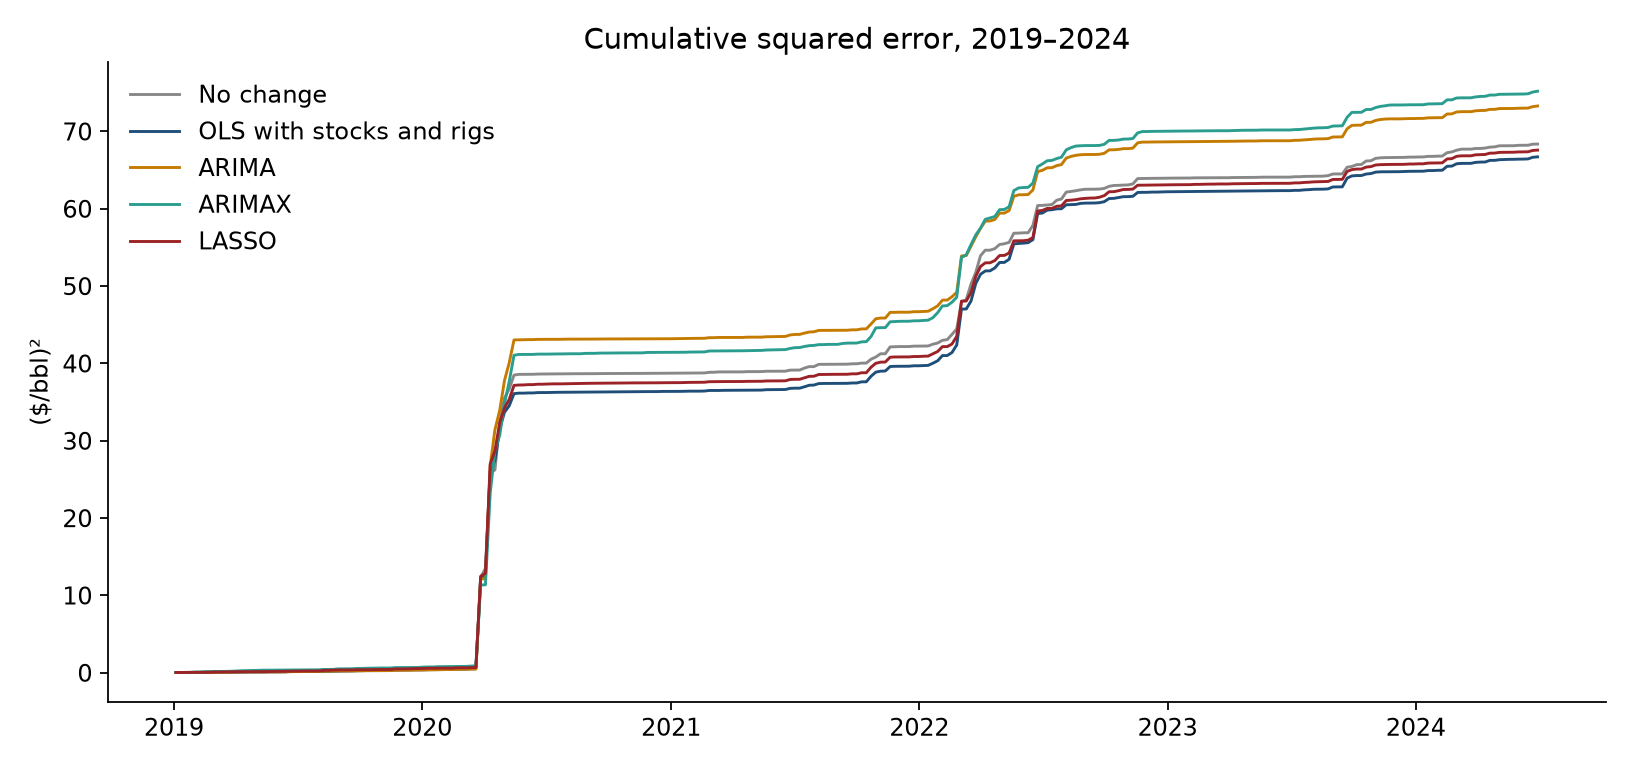

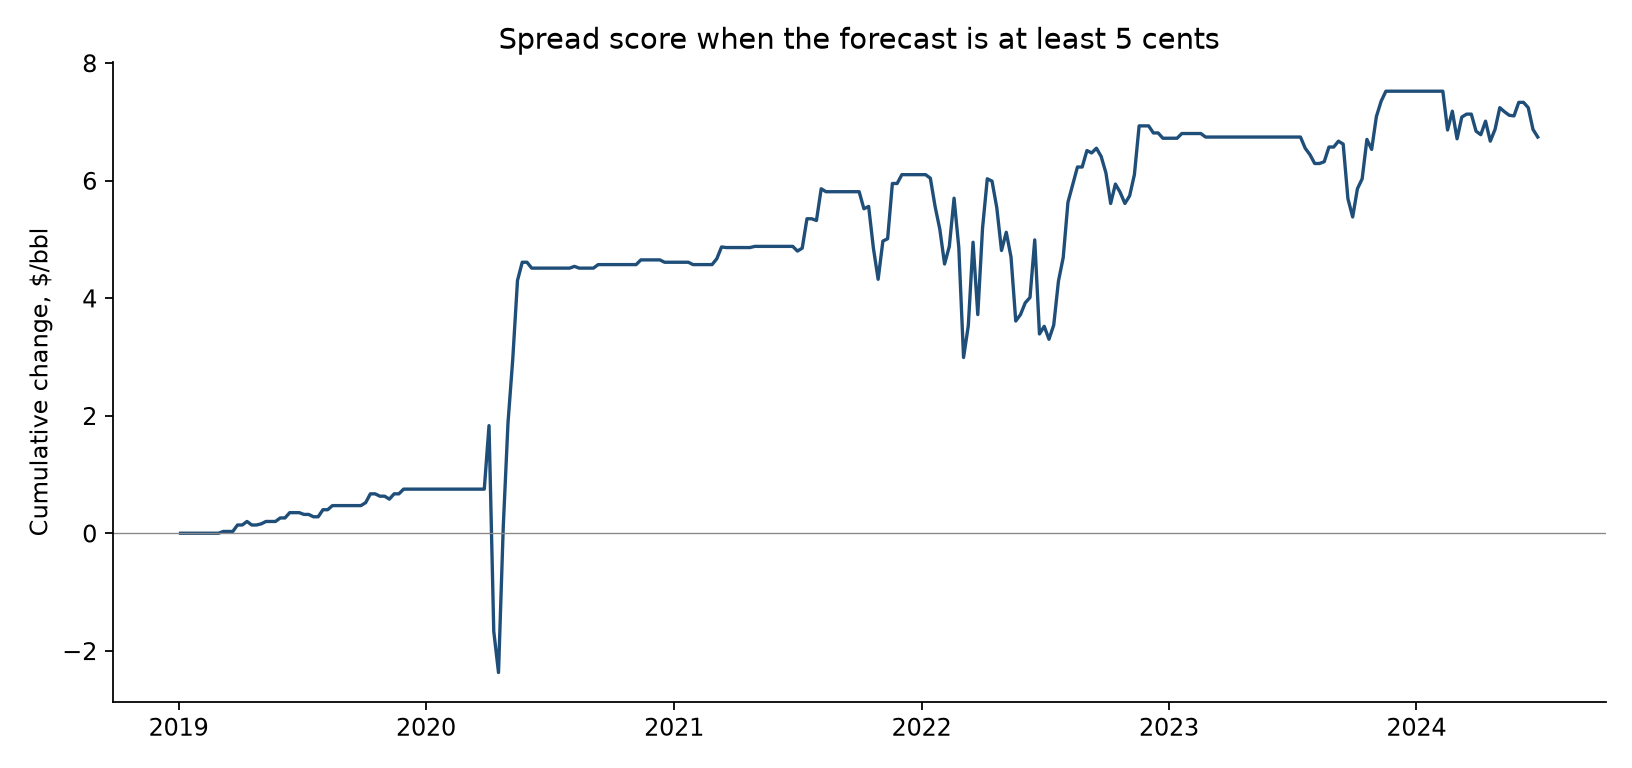

,variable,coefficient
0,spread,-0.122374
1,stock_change,0.022377
2,rig_change,0.000000
3,production_change,0.011532
4,position_change,-0.000000
5,crack_change,0.008396
6,vix_change,-0.006114
7,ip_growth,-0.016684
8,dollar_return,-0.000000
9,gasoline_change,-0.043622


In [8]:
show(Image(analysis.OUT / "cumulative_error.png"))
show(Image(analysis.OUT / "trading.png"))
pd.read_csv(analysis.OUT / "lasso_coefficients.csv")


## 6. What to take into the note

The reported model is the three-variable weekly OLS at the top. The data are the daily prices and the weekly industry sheet in `Oil Data.xlsx`, inside the window the definitions sheet names. Stocks have the right sign in the pre-2019 fit and do not improve the holdout. The monthly yields were tested in LASSO and ridge and do not replace the Friday regression. The gain over predicting no change is about half a cent of root-mean-square error. The week ending 10 April 2020, a forecast of âˆ’$0.15 against a move of +$3.50, is the shock the regression does not see.
